In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras import layers, models

In [20]:
# 1. Baca data mentah UCI (pisahkan titik koma, tangani missing value '?')
df_raw = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False,
)

# 2. Gabungkan kolom Date dan Time menjadi DatetimeIndex
df_raw["Datetime"] = pd.to_datetime(
    df_raw["Date"] + " " + df_raw["Time"], format="%d/%m/%Y %H:%M:%S"
)
df_raw.set_index("Datetime", inplace=True)

# 3. Ambil kolom Global_active_power, isi nilai kosong dengan interpolasi
series_kw = df_raw["Global_active_power"].interpolate(method="linear")

# 4. Resample menjadi interval 15 menit dan ubah kW ke kWh (daya * 0.25 jam)
df_15m = pd.DataFrame()
df_15m["energy_kwh"] = series_kw.resample("15min").mean() * 0.25

# 5. Rekayasa Fitur Input (X: 8 Fitur)
df_features = pd.DataFrame(index=df_15m.index)

# 4 Lag Features (Momentum 1 Jam Terakhir)
df_features["x0_energy_t0"] = df_15m["energy_kwh"]
df_features["x1_energy_t1"] = df_15m["energy_kwh"].shift(1)
df_features["x2_energy_t2"] = df_15m["energy_kwh"].shift(2)
df_features["x3_energy_t3"] = df_15m["energy_kwh"].shift(3)

# 4 Baseline Rolling Means (Blok 6-Jaman dalam 24 Jam Terakhir)
# 6 jam = 24 data poin (karena per 15 menit)
df_features["x4_baseline_0_6h"] = (
    df_15m["energy_kwh"].shift(1).rolling(window=24).mean()
)
df_features["x5_baseline_6_12h"] = (
    df_15m["energy_kwh"].shift(25).rolling(window=24).mean()
)
df_features["x6_baseline_12_18h"] = (
    df_15m["energy_kwh"].shift(49).rolling(window=24).mean()
)
df_features["x7_baseline_18_24h"] = (
    df_15m["energy_kwh"].shift(73).rolling(window=24).mean()
)

# 6. Pembuatan Target Horizon Output (Y: 4 Horizon Masa Depan)
# Jumlahkan konsumsi ke depan (shift negatif)
df_features["target_q1_0_6h"] = sum(
    df_15m["energy_kwh"].shift(-i) for i in range(1, 25)
)
df_features["target_q2_6_12h"] = sum(
    df_15m["energy_kwh"].shift(-i) for i in range(25, 49)
)
df_features["target_q3_12_18h"] = sum(
    df_15m["energy_kwh"].shift(-i) for i in range(49, 73)
)
df_features["target_q4_18_24h"] = sum(
    df_15m["energy_kwh"].shift(-i) for i in range(73, 97)
)

# 7. Buang baris NaN akibat shifting awal & akhir
dataset_final = df_features.dropna()

# 8. Simpan ke berkas CSV yang siap dimasukkan ke pipeline model
dataset_final.to_csv("tinyml_energy_features.csv", index=False)
print("Transformasi selesai! Bentuk dataset akhir:", dataset_final.shape)

Transformasi selesai! Bentuk dataset akhir: (138160, 12)


## 1. Pemisahan Fitur ($X$), Target ($Y$), dan Pembagian Data Latih-Validasi
Matriks dipisahkan menjadi 8 kolom fitur masukan ($X \in \mathbb{R}^8$) dan 4 kolom target keluaran ($Y \in \mathbb{R}^4$). Data kemudian dibagi menjadi set data latih (training set) dan validasi (validation set), umumnya dengan rasio 80:20.  

In [21]:
# Memuat dataset fitur yang telah dibuat sebelumnya
df = pd.read_csv("tinyml_energy_features.csv")

# 1. Pisahkan Fitur Masukan (X) dan Target Keluaran (Y)
feature_cols = [
    "x0_energy_t0",
    "x1_energy_t1",
    "x2_energy_t2",
    "x3_energy_t3",
    "x4_baseline_0_6h",
    "x5_baseline_6_12h",
    "x6_baseline_12_18h",
    "x7_baseline_18_24h",
]

target_cols = [
    "target_q1_0_6h",
    "target_q2_6_12h",
    "target_q3_12_18h",
    "target_q4_18_24h",
]

X = df[feature_cols].values
Y = df[target_cols].values

# 2. Bagi dataset menjadi Train (80%) dan Validation (20%)
# Mengingat sifat time-series, shuffle=False menjaga urutan temporal alami
X_train, X_val, Y_train, Y_val = train_test_split(
    X, Y, test_size=0.2, shuffle=False
)

## 2. Standarisasi Fitur (Z-Score Normalization)
Jaringan saraf tiruan membutuhkan skala data yang konsisten agar gradien bobot tidak meledak (exploding gradient). Standarisasi $Z\text{-score}$ dihitung hanya dari data latih ($X_{train}$) guna menghindari kebocoran data (data leakage)

$$x_{norm} = \frac{x - \mu}{\sigma + \epsilon}$$

Parameter nilai $\mu$ (mean) dan $\sigma$ (standard deviation) ini wajib diekspor karena akan digunakan kembali oleh mikrokontroler ESP32 saat proses inferensi langsung.

In [22]:
# Hitung parameter rata-rata (mean) dan standar deviasi (std) dari X_train
mean_X = np.mean(X_train, axis=0)
std_X = np.std(X_train, axis=0)
epsilon = 1e-7

# Normalisasi data latih dan data validasi
X_train_norm = (X_train - mean_X) / (std_X + epsilon)
X_val_norm = (X_val - mean_X) / (std_X + epsilon)

# Simpan parameter normalisasi ke array file agar nanti bisa diekspor ke C++
np.save("feature_mean.npy", mean_X)
np.save("feature_std.npy", std_X)

## 3. Membangun Pipeline Data Menggunakan tf.data.Dataset
Mengikuti pola pipeline TensorFlow berkinerja tinggi, data dibungkus dalam objek tf.data.Dataset yang dilengkapi mekanisme pengelompokan (batching), pengacakan (shuffling), dan prefetching agar proses pemuatan data di CPU berjalan bersamaan dengan kalkulasi di GPU.   

In [23]:
BATCH_SIZE = 64

# Pipeline data latih: diacak (shuffle), dikelompokkan batch, dan di-prefetch
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train_norm, Y_train))
    .shuffle(buffer_size=10000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Pipeline data validasi: langsung batch dan prefetch
val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val_norm, Y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

## 4. Mendefinisikan Arsitektur Model AR-MLP ($8 \to 16 \to 8 \to 4$)
Model dibangun menggunakan tf.keras.Sequential yang dioptimalkan untuk inferensi perangkat keras mikro (TinyML) pada tugas regresi deret waktu multi-cakrawala (multi-horizon time-series regression):
- Input Layer: Menerima 8 nilai fitur dinamika deret waktu hasil rekayasa fitur (lag konsumsi energi sesaat dan rolling baseline siklus sirkadian).
- Hidden Layer 1: 16 neuron terhubung penuh (Dense) dengan fungsi aktivasi LeakyReLU(negative_slope=0.01) untuk mempertahankan gradien pembaruan bobot pada nilai negatif dan mencegah matinya neuron (dying ReLU problem).
- Hidden Layer 2: 8 neuron terhubung penuh (Dense) dengan fungsi aktivasi LeakyReLU(negative_slope=0.01) guna mengekstraksi representasi tren konsumsi jangka menengah.
- Output Layer: 4 neuron proyeksi kebutuhan energi ($Q_1, Q_2, Q_3, Q_4$) menggunakan aktivasi linear (tanpa fungsi pemotong gradien). Penggunaan aktivasi linear menjaga aliran gradien backpropagation tetap aktif selama proses optimasi, menghindari kegagalan gradien nol permanen pada salah satu horizon peramalan. Pembatasan fisik nilai konsumsi non-negatif ($Q_m \ge 0{,}0\text{ kWh}$) ditangani melalui pemotongan nilai (clipping $\max(0.0f, z)$) pada tahap inferensi pasca-komputasi di mikrokontroler ESP32.   

In [ ]:
# Ubah output layer ke linear agar gradien tidak terkunci mati
model = models.Sequential(
    [
        layers.Input(shape=(8,), name="input_features"),
        layers.Dense(16, name="hidden_layer_1"),
        layers.LeakyReLU(negative_slope=0.01, name="leaky_relu_1"),
        layers.Dense(8, name="hidden_layer_2"),
        layers.LeakyReLU(negative_slope=0.01, name="leaky_relu_2"),
        # Output layer menggunakan linear untuk menjaga kestabilan gradien regresi
        layers.Dense(4, activation="linear", name="output_horizons"),
    ]
)

# Gunakan learning rate sedikit lebih adaptif
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])

## 5. Kompilasi dan Pelatihan Model (Compile & Fit)
Sebelum proses pelatihan dimulai, ditentukan konfigurasi pengoptimalan:Optimizer: Adam dengan laju pembelajaran (learning rate) $0{,}001$.   Loss Function: Mean Squared Error (MSE) sebagai pengukur deviasi prediksi terhadap konsumsi aktual.   Metrics: Mean Absolute Error (MAE) untuk memantau selisih rata-rata energi dalam satuan kWh riil.   Callback: EarlyStopping untuk menghentikan pelatihan secara otomatis saat nilai kerugian validasi tidak lagi membaik dan memulihkan bobot terbaik.   

In [ ]:
# Kompilasi model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"],
)

# Callback untuk mencegah overfitting
early_stop = EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True, verbose=1
)

# Melatih model
EPOCHS = 100
history = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[early_stop]
)

Epoch 1/100


/home/ridho/ngoding/IoT Prediksi kWh/pelatihan/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1727/1727 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 17.6161 - mae: 3.0172 - val_loss: 7.0293 - val_mae: 2.0807
Epoch 2/100
1727/1727 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 11.4578 - mae: 2.5224 - val_loss: 6.8694 - val_mae: 2.0329
Epoch 3/100
1727/1727 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 11.2876 - mae: 2.5025 - val_loss: 6.9478 - val_mae: 2.0528
Epoch 4/100
1727/1727 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 11.1690 - mae: 2.4889 - val_loss: 6.9204 - val_mae: 2.0547
Epoch 5/100
1727/1727 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 11.0987 - mae: 2.4778 - val_loss: 7.1067 - val_mae: 2.0984
Epoch 6/100
1727/1727 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 11.0517 - mae: 2.4729 - val_loss: 6.8642 - val_mae: 2.0176
Epoch 7/100
1727/1727 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 11.0090 - mae: 2.4640 - val_loss: 6.8438 - val_mae: 2.0051
Epoch 8/100
1727/1727 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 10.9617 - mae: 2.4581 - val_loss: 7.0399 - val_mae: 2.0618
Epoch 9/100
1727/1727 ━━━━━━━━━━━━━━

## 6. Menyimpan Model Dasar (Pre-Trained Base Weights)
Setelah pelatihan selesai, simpan model dan bobot internalnya. Berkas ini menjadi aset dasar (base knowledge) yang siap di-fine-tune pada tahap berikutnya menggunakan data manual 48 jam yang diperoleh dari prototipe fisik ESP32.

In [26]:
# Simpan model dasar lengkap dalam format modern Keras
model.save("pretrained_energy_model.keras")

# Simpan bobotnya saja untuk kemudahan inisialisasi transfer learning
model.save_weights("pretrained_weights.weights.h5")

print(
    "Tahap Pre-training selesai! Model dasar dan bobot awal berhasil disimpan."
)

Tahap Pre-training selesai! Model dasar dan bobot awal berhasil disimpan.


In [1]:
import numpy as np
import tensorflow as tf

# 1. Muat model dan parameter normalisasi
model = tf.keras.models.load_model("pretrained_energy_model.keras")
mean_X = np.load("feature_mean.npy")
std_X = np.load("feature_std.npy")

# Ambil bobot tiap layer
w1, b1 = model.get_layer("hidden_layer_1").get_weights()
w2, b2 = model.get_layer("hidden_layer_2").get_weights()
w3, b3 = model.get_layer("output_horizons").get_weights()


def to_c_array(arr, name):
  flat = arr.flatten()
  s = f"const float {name}[{len(flat)}] = {{\n  "
  s += ", ".join([f"{v:.7f}f" for v in flat])
  s += "\n};\n"
  return s


# 2. Tulis ke file header C++
with open("tinyml_model.h", "w") as f:
  f.write("#ifndef TINYML_MODEL_H\n#define TINYML_MODEL_H\n\n")
  f.write("// Parameter Normalisasi Z-Score\n")
  f.write(to_c_array(mean_X, "FEATURE_MEAN"))
  f.write(to_c_array(std_X, "FEATURE_STD"))

  f.write("\n// Bobot Layer 1 (Dense 8 -> 16)\n")
  f.write(to_c_array(w1, "W_LAYER1"))
  f.write(to_c_array(b1, "B_LAYER1"))

  f.write("\n// Bobot Layer 2 (Dense 16 -> 8)\n")
  f.write(to_c_array(w2, "W_LAYER2"))
  f.write(to_c_array(b2, "B_LAYER2"))

  f.write("\n// Bobot Output Layer (Dense 8 -> 4)\n")
  f.write(to_c_array(w3, "W_LAYER3"))
  f.write(to_c_array(b3, "B_LAYER3"))

  f.write("\n#endif // TINYML_MODEL_H\n")

print(
    "Berhasil! File tinyml_model.h siap disalin ke folder sketch Arduino ESP32."
)

I0000 00:00:1791497948.873181  554811 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791497949.718016  554811 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791497953.393417  554811 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Berhasil! File tinyml_model.h siap disalin ke folder sketch Arduino ESP32.


E0000 00:00:1791497956.171428  554811 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 7. Evaluasi Menyeluruh Menggunakan Data Uji Independen
Data pengujian (test set) harus terpisah sepenuhnya dari data pelatihan dan validasi untuk memastikan model tidak mengalami kondisi overfitting.   

In [ ]:
# 1. Memuat Model dan Parameter Normalisasi
model = tf.keras.models.load_model("pretrained_energy_model.keras")
mean_X = np.load("feature_mean.npy")
std_X = np.load("feature_std.npy")

# 2. Menyiapkan Dataset Uji (Test Set yang belum pernah dilihat model)
# Misal mengambil 15% subset data terakhir dari rekaman deret waktu
df_test = pd.read_csv("tinyml_energy_features.csv").tail(200)

feature_cols = [
    "x0_energy_t0",
    "x1_energy_t1",
    "x2_energy_t2",
    "x3_energy_t3",
    "x4_baseline_0_6h",
    "x5_baseline_6_12h",
    "x6_baseline_12_18h",
    "x7_baseline_18_24h",
]
target_cols = [
    "target_q1_0_6h",
    "target_q2_6_12h",
    "target_q3_12_18h",
    "target_q4_18_24h",
]

X_test_raw = df_test[feature_cols].values
Y_test_actual = df_test[target_cols].values

# 3. Standardisasi Fitur Uji Menggunakan Mean & Std Data Training
X_test_norm = (X_test_raw - mean_X) / (std_X + 1e-7)

# 4. Evaluasi Resmi via Keras API
test_ds = tf.data.Dataset.from_tensor_slices((X_test_norm, Y_test_actual)).batch(
    32
)
loss_test, mae_test = model.evaluate(test_ds, verbose=0)
print(f"Hasil Evaluasi Global Model pada Data Test:")
print(f" • Test Loss (MSE) : {loss_test:.6f}")
print(f" • Test MAE        : {mae_test:.4f} kWh")

# 5. Prediksi Inferensi
Y_test_pred = model.predict(X_test_norm)

# 6. Analisis Error per Horizon Waktu (Q1, Q2, Q3, Q4)
horizons = [
    "0-6 Jam (Q1)",
    "6-12 Jam (Q2)",
    "12-18 Jam (Q3)",
    "18-24 Jam (Q4)",
]
print("\nEvaluasi Kinerja per Blok Horizon:")
for i, h_name in enumerate(horizons):
  mae_h = mean_absolute_error(Y_test_actual[:, i], Y_test_pred[:, i])
  rmse_h = np.sqrt(mean_squared_error(Y_test_actual[:, i], Y_test_pred[:, i]))
  mape_h = (
      np.mean(
          np.abs(
              (Y_test_actual[:, i] - Y_test_pred[:, i])
              / (Y_test_actual[:, i] + 1e-5)
          )
      )
      * 100
  )
  print(
      f" - Horizon {h_name} -> MAE: {mae_h:.4f} kWh | RMSE: {rmse_h:.4f} kWh |"
      f" MAPE: {mape_h:.2f}%"
  )

Hasil Evaluasi Global Model pada Data Test:
 • Test Loss (MSE) : 4.919711
 • Test MAE        : 1.7538 kWh
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

Evaluasi Kinerja per Blok Horizon:
 - Horizon 0-6 Jam (Q1) -> MAE: 1.5763 kWh | RMSE: 2.0779 kWh | MAPE: 33.38%
 - Horizon 6-12 Jam (Q2) -> MAE: 1.6200 kWh | RMSE: 2.0751 kWh | MAPE: 38.47%
 - Horizon 12-18 Jam (Q3) -> MAE: 1.7923 kWh | RMSE: 2.2297 kWh | MAPE: 38.60%
 - Horizon 18-24 Jam (Q4) -> MAE: 2.0265 kWh | RMSE: 2.4665 kWh | MAPE: 47.87%


## 8. Visualisasi Kurva Prediksi vs Aktual
Visualisasi grafik deret waktu diperlukan untuk menganalisis apakah kurva prediksi mampu mengikuti dinamika tarikan daya nyata.

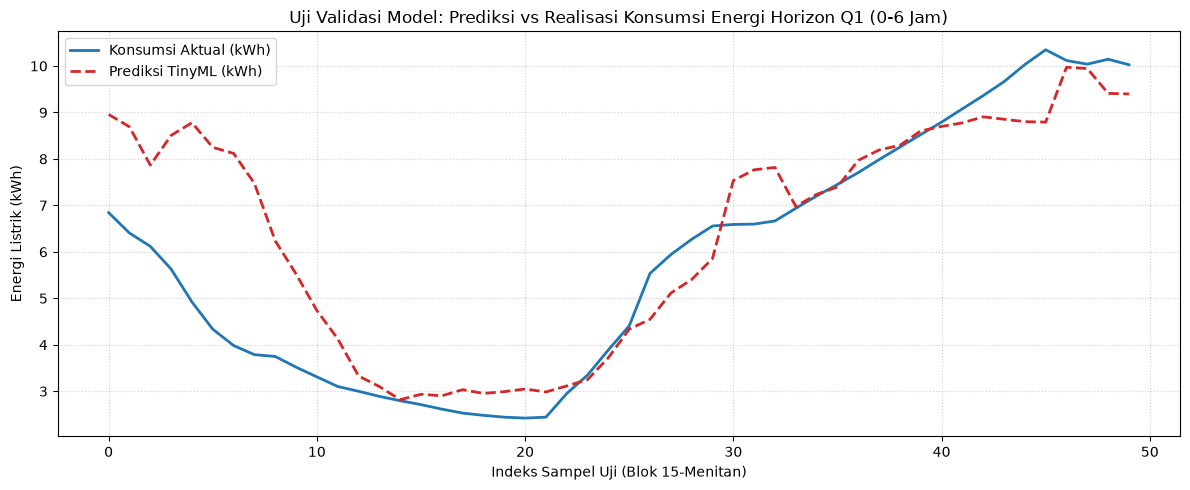

In [28]:
plt.figure(figsize=(12, 5))
# Menampilkan perbandingan horizon terdekat (Q1: 0-6 Jam)
plt.plot(
    Y_test_actual[:50, 0],
    label="Konsumsi Aktual (kWh)",
    color="#1f77b4",
    linewidth=2,
)
plt.plot(
    Y_test_pred[:50, 0],
    label="Prediksi TinyML (kWh)",
    color="#d62728",
    linestyle="--",
    linewidth=2,
)
plt.title(
    "Uji Validasi Model: Prediksi vs Realisasi Konsumsi Energi Horizon Q1 (0-6"
    " Jam)"
)
plt.xlabel("Indeks Sampel Uji (Blok 15-Menitan)")
plt.ylabel("Energi Listrik (kWh)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()